[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/santialferez/FDLE/blob/main/S1_CNN/S1_CNN_STUDENT.ipynb)

# CNN I: convolution, pooling and a first CNN

**Foundations of Deep Learning for Engineering · Convolutional networks, Session 1 of 2 (week 8)** · EEBE, UPC

Two weeks ago your MLP reached about 98% on MNIST with 50,890 parameters. Today you will see why images need a layer of their own:

1. an MLP forgets the grid and breaks when the digit moves a few pixels,
2. a **convolution** slides one small kernel over the whole image (shared weights),
3. padding, stride and pooling control the output size,
4. a small **CNN** with almost the same number of parameters makes fewer errors, and the gap grows on colour images (CIFAR-10).

Work **in pairs** in Google Colab. *Runtime → Change runtime type → T4 GPU*.

- **Part A · Follow along** (cells ▶ S1·A0 to S1·A9). We run them together during the lecture. Each slide "PYTHON EXERCISE S1·An" tells you which cell to run.
- **Part B · Workshop** (TODO 1 to 5, Q1 to Q6, 🔬). The last 35 minutes, in pairs.

### How to use this notebook

| Icon | Meaning |
|:-:|:-|
| ▶ | run the cell as it is |
| ✏️ **TODO** | complete the code: replace every `___` with the right expression (the slides guide you) |
| ❓ | closed question: choose an option or give a number |
| 💬 | open question: discuss with your partner and write two or three sentences |
| 🔬 | experiment: change the settings and compare |
| ✅ | self-check: prints ✅ when your code is right (nothing is graded) |

Nothing in this notebook is graded. Change things, break things, and compare.

**About LLMs.** You may use an LLM (ChatGPT, Claude, Gemini, ...) to understand an error message or a concept. Do not use it to fill the blanks: the blanks are exactly the lines you should be able to write yourself.

## Outline

**Part A · Follow along**: we run each cell when its slide comes up in the lecture (about 2 minutes of GPU time in total, most of it in A2, A7 and A9, which train).

| Cell | What it does | Slide |
|:-|:-|:-:|
| ▶ S1·A0 | Download the data | 4 |
| ▶ S1·A1 | An image is a grid, a vector forgets it | 7 |
| ▶ S1·A2 | Your MLP breaks when the digit moves 3 pixels · ❓ A2 question | 10 |
| ▶ S1·A3 | A hand-made kernel on a real digit · ❓ A3 question | 19, 20 |
| ▶ S1·A4 | Predict the output shape of three `nn.Conv2d` settings | 28 |
| ▶ S1·A5 | Max-pooling the Bishop matrix, then the edge maps | 39 |
| ▶ S1·A6 | `ConvNet` as an `nn.Module`, and its parameter count · ❓ A6 question | 48 |
| ▶ S1·A7 | CNN vs MLP on MNIST: same parameters, fewer errors | 51 |
| ▶ S1·A8 | The shift test again: MLP vs CNN | 52 |
| ▶ S1·A9 | Colour images: CIFAR-10, the gap grows | 53, 54 |

**Part B · Workshop**: the last 35 minutes of the session, in pairs (slide 55).

| Step | What it does | Slide |
|:-|:-|:-:|
| ✏️ TODO 1 | Convolution by hand, then in code | 56 |
| ✏️ TODO 2 | The output-size formula | 57 |
| ✏️ TODO 3 | Counting the parameters of a convolution | 58 |
| ✏️ TODO 4 | A deeper network: `ConvNet2` with three blocks | 59 |
| ✏️ TODO 5 | Train `ConvNet2` on CIFAR-10 | 60 |
| ❓ 💬 Q1 to Q6 | after TODO 2: ❓ Q1 · after TODO 3: ❓ Q4 · after TODO 4: ❓ Q2 · after TODO 5: 💬 Q5, Q3, Q6 |  |
| 🔬 | Free experiment: your own CNN |  |

Slide numbers are those of the lecture deck (title slide = 1); each cell below shows a thumbnail.

## Part 0 · Setup ▶

Run this cell first. It imports the libraries, finds the GPU and defines the helpers we use all session:

- `check(cond, ok_msg, hint)` prints ✅ or ❌ with a hint. It is only for you.
- `set_seed(s)` fixes the random numbers (same seed, same result).
- `count_params(model)` counts weights and biases; `evaluate(model, X, y)` returns the accuracy (between 0 and 1).
- `fit(model, X_train, y_train, X_val, y_val, epochs, lr, batch_size, name)` is the training loop of Session 2 (mini-batches, Adam, cross-entropy). It prints one line per epoch and adds a row to the table `RESULTS`; `show_results()` prints that table.
- `shift_test(model, X, y)` moves every image 0, 1, 2, 3 and 4 pixels to the right and measures the accuracy each time.

In [ ]:
# ▶ S1·0
import os, time, json, random
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import torch
from torch import nn
import torch.nn.functional as F
import torchvision

FAST = os.environ.get("FAST") == "1"      # FAST=1: small subsets and 1 epoch (only to test the notebook)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "· device:", device, "· FAST mode" if FAST else "")
if device == "cpu":
    print("No GPU: Runtime → Change runtime type → T4 GPU (the notebook also runs on a CPU, only slower).")

MLP_COLOR, CNN_COLOR = "#C9423A", "#1F8A8A"     # red = MLP, teal = CNN in every chart
DIV_CMAP = LinearSegmentedColormap.from_list("red_white_teal", [MLP_COLOR, "#FFFFFF", CNN_COLOR])
RESULTS = []                                     # one row per trained model (filled by fit)


def set_seed(s=0):
    """Same seed -> same random numbers -> same results (reproducibility)."""
    random.seed(s)
    np.random.seed(s)
    torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)


def check(cond, ok_msg, hint):
    """Self-check: prints ✅ when the condition holds, otherwise ❌ with a hint. Nothing is graded."""
    print(("✅ " + ok_msg) if cond else ("❌ Not yet. Hint: " + hint))


def count_params(model):
    """Number of trainable parameters (weights and biases)."""
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


@torch.no_grad()
def predict(model, X, batch_size=1000):
    """Predicted class of every image in X (in batches, so the GPU memory is enough)."""
    model.eval()
    return torch.cat([model(X[i:i + batch_size]).argmax(dim=1) for i in range(0, len(X), batch_size)])


def evaluate(model, X, y):
    """Accuracy of the model on images X with labels y: a number between 0 and 1."""
    return (predict(model, X) == y).float().mean().item()


def fit(model, X_train, y_train, X_val, y_val, epochs=2, lr=1e-3, batch_size=128, name=None):
    """Mini-batch training with Adam and cross-entropy; the data stay on `device`.
    Prints one line per epoch, returns dict(train_loss, val_acc) and adds a row to RESULTS."""
    name = name or model.__class__.__name__
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()              # takes logits: no softmax in forward
    hist = dict(train_loss=[], val_acc=[])
    n, t0 = len(X_train), time.time()
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(n, device=X_train.device)
        total = torch.zeros((), device=X_train.device)
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            xb, yb = X_train[idx], y_train[idx]
            loss = loss_fn(model(xb), yb)        # 1. forward, 2. loss
            optimizer.zero_grad()
            loss.backward()                      # 3. backward (gradients)
            optimizer.step()                     # 4. update the parameters
            total += loss.detach() * len(idx)
        hist["train_loss"].append(total.item() / n)
        hist["val_acc"].append(evaluate(model, X_val, y_val))
        print(f"{name} · epoch {epoch + 1}/{epochs} · train loss {hist['train_loss'][-1]:.4f} · "
              f"val acc {100 * hist['val_acc'][-1]:.1f}% · {time.time() - t0:.0f} s")
    acc = hist["val_acc"][-1]
    RESULTS.append(dict(name=name, params=count_params(model), val_acc=acc,
                        errors=int(round((1 - acc) * len(y_val))), n_val=len(y_val),
                        epochs=epochs, time_s=round(time.time() - t0, 1)))
    return hist


def result(name):
    """The last row of RESULTS with this name."""
    return [r for r in RESULTS if r["name"] == name][-1]


def show_results():
    """Print the table of every model trained so far."""
    print(f"{'model':42s} {'params':>9s} {'val acc':>8s}   errors")
    for r in RESULTS:
        print(f"{r['name']:42s} {r['params']:>9,} {100 * r['val_acc']:7.1f}%   "
              f"{r['errors']:,} / {r['n_val']:,}")


def plot_history(hist, title=""):
    """Training loss and validation accuracy per epoch."""
    ep = np.arange(1, len(hist["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(9, 3))
    ax[0].plot(ep, hist["train_loss"], "o-"); ax[0].set_title("train loss"); ax[0].set_xlabel("epoch")
    ax[1].plot(ep, 100 * np.array(hist["val_acc"]), "o-"); ax[1].set_title("validation accuracy (%)")
    ax[1].set_xlabel("epoch")
    fig.suptitle(title); plt.tight_layout(); plt.show()


def show_grid(images, titles=None, ncols=8, size=1.4, cmap="gray"):
    """Show a few images (N, C, H, W) or (N, H, W) in a grid; each image is scaled to [0, 1]."""
    images = images.detach().float().cpu()
    if images.ndim == 3:
        images = images.unsqueeze(1)
    n = len(images)
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows * 1.15), squeeze=False)
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i >= n:
            continue
        im = images[i]
        im = (im - im.min()) / (im.max() - im.min() + 1e-8)
        if im.shape[0] == 1:
            ax.imshow(im[0], cmap=cmap)
        else:
            ax.imshow(im.permute(1, 2, 0))
        if titles is not None and i < len(titles) and titles[i]:
            ax.set_title(titles[i], fontsize=9)
    plt.tight_layout(); plt.show()


def shift_images(X, s, fill=None):
    """Move every image s pixels to the right. The new columns get the background value
    (black, i.e. 0 before normalization); we pad and crop, nothing wraps around."""
    if s == 0:
        return X
    fill = X.min().item() if fill is None else fill
    return F.pad(X, (s, 0), value=fill)[..., :X.shape[-1]]


def shift_test(model, X, y, shifts=(0, 1, 2, 3, 4)):
    """Accuracy of the model when every image is moved 0, 1, 2, ... pixels to the right."""
    accs = [evaluate(model, shift_images(X, s), y) for s in shifts]
    print("shift (px):  " + "  ".join(f"{s:>6d}" for s in shifts))
    print("accuracy:    " + "  ".join(f"{100 * a:5.1f}%" for a in accs))
    return accs


print("Helpers ready.")

## Part A · Follow along

### ▶ S1·A0 · Download the data (run it now, it takes about one minute)

*Slide: AGENDA (slide 4).*

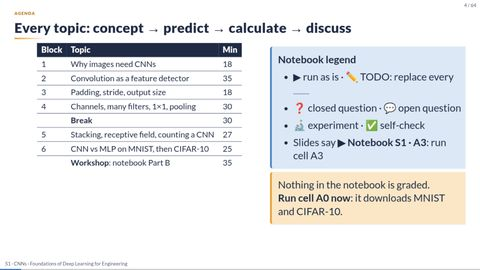

<sub>Slide 4 · Every topic: concept → predict → calculate → discuss</sub>

We use two datasets:

- **MNIST**: 60,000 training images of handwritten digits, 1 × 28 × 28. We keep 50,000 for training and 10,000 for validation, as in Session 2.
- **CIFAR-10**: 50,000 colour photos, 3 × 32 × 32, in 10 classes. Its 10,000 test images are our validation set. The cell loads it from the Hugging Face mirror (about 10 s); if that fails it tries the original site (slow), and if that fails too it uses Fashion-MNIST instead (`CIFAR_OK = False`).

The images are stored as **normalized tensors on the GPU** with shape `(N, C, H, W)`: number of images, channels, height, width. The mean and the standard deviation come from the training images only.

In [ ]:
# ▶ S1·A0
DATA = "./data"
N_TRAIN, N_VAL = (10_000, 2_000) if FAST else (None, None)   # None = all images
EPOCHS_MNIST = 1 if FAST else 5
EPOCHS_CIFAR = 1 if FAST else 5


def to_images(data):
    """uint8 (N, H, W) or (N, H, W, 3) -> float tensor (N, C, H, W) with values in [0, 1]."""
    x = torch.as_tensor(np.asarray(data)).float() / 255
    return x.unsqueeze(1) if x.ndim == 3 else x.permute(0, 3, 1, 2).contiguous()


t0 = time.time()
# ---- MNIST: 50,000 train / 10,000 validation from the 60,000 training images
mnist = torchvision.datasets.MNIST(DATA, train=True, download=True)
X_all, y_all = to_images(mnist.data), mnist.targets.clone()
perm = torch.randperm(60_000, generator=torch.Generator().manual_seed(0))
tr, va = perm[:50_000][:N_TRAIN], perm[50_000:][:N_VAL]
MNIST_MEAN, MNIST_STD = X_all[tr].mean().item(), X_all[tr].std().item()
X_train = ((X_all[tr] - MNIST_MEAN) / MNIST_STD).to(device)
X_val = ((X_all[va] - MNIST_MEAN) / MNIST_STD).to(device)
y_train, y_val = y_all[tr].to(device), y_all[va].to(device)
print(f"MNIST   train {tuple(X_train.shape)} · val {tuple(X_val.shape)} · "
      f"mean {MNIST_MEAN:.4f}, std {MNIST_STD:.4f}")

# ---- CIFAR-10: 50,000 train / 10,000 validation (the official test set)
CIFAR_CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
HF_CIFAR = "https://huggingface.co/datasets/uoft-cs/cifar10/resolve/main/plain_text/"


def cifar10_from_huggingface(split):
    """The official CIFAR-10 mirrored on Hugging Face (parquet, PNG bytes). Fast from Colab."""
    import io, pandas as pd
    from PIL import Image
    df = pd.read_parquet(HF_CIFAR + f"{split}-00000-of-00001.parquet")
    imgs = np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in df["img"]])  # (N, 32, 32, 3) uint8
    return imgs, torch.tensor(df["label"].to_numpy())


def cifar10_from_torchvision(split):
    """The original site (www.cs.toronto.edu), sometimes very slow."""
    ds = torchvision.datasets.CIFAR10(DATA, train=(split == "train"), download=True)
    return ds.data, torch.tensor(ds.targets)


try:
    try:
        tr_np, yc_tr = cifar10_from_huggingface("train")
        te_np, yc_va = cifar10_from_huggingface("test")
    except Exception as e:                               # mirror unavailable: try the original site
        print("Hugging Face mirror failed:", repr(e)[:100], "-> trying the original site (slow)")
        tr_np, yc_tr = cifar10_from_torchvision("train")
        te_np, yc_va = cifar10_from_torchvision("test")
    Xc_tr, Xc_va = to_images(tr_np), to_images(te_np)
    CIFAR_OK, DS_C = True, "CIFAR-10"
except Exception as e:                                   # no CIFAR-10 at all: fallback
    print("CIFAR-10 download failed:", repr(e)[:120], "-> using Fashion-MNIST instead")
    f_tr = torchvision.datasets.FashionMNIST(DATA, train=True, download=True)
    f_te = torchvision.datasets.FashionMNIST(DATA, train=False, download=True)
    Xc_tr, yc_tr = to_images(f_tr.data), f_tr.targets.clone()
    Xc_va, yc_va = to_images(f_te.data), f_te.targets.clone()
    CIFAR_CLASSES, CIFAR_OK, DS_C = f_tr.classes, False, "Fashion-MNIST"
Xc_tr, yc_tr, Xc_va, yc_va = Xc_tr[:N_TRAIN], yc_tr[:N_TRAIN], Xc_va[:N_VAL], yc_va[:N_VAL]
CIFAR_MEAN = Xc_tr.mean(dim=(0, 2, 3), keepdim=True)      # one mean and one std per colour channel
CIFAR_STD = Xc_tr.std(dim=(0, 2, 3), keepdim=True)
Xc_train = ((Xc_tr - CIFAR_MEAN) / CIFAR_STD).to(device)
Xc_val = ((Xc_va - CIFAR_MEAN) / CIFAR_STD).to(device)
yc_train, yc_val = yc_tr.to(device), yc_va.to(device)
C_IN_C, HW_C = Xc_train.shape[1], Xc_train.shape[-1]      # 3 channels, 32 × 32 for CIFAR-10
del X_all, y_all, Xc_tr, Xc_va
print(f"{DS_C:8s}train {tuple(Xc_train.shape)} · val {tuple(Xc_val.shape)} · CIFAR_OK = {CIFAR_OK}")
print(f"data ready in {time.time() - t0:.0f} s")
check(tuple(X_train.shape[1:]) == (1, 28, 28) and len(X_val) == (2_000 if FAST else 10_000),
      "MNIST ready: (N, 1, 28, 28) tensors, 10,000 validation images",
      "rerun the cell; if the download fails, Runtime → Restart session")

### ▶ S1·A1 · An image is a grid, a vector forgets it

*Slide: "An image is a grid; flattening forgets the grid" (slide 7).*

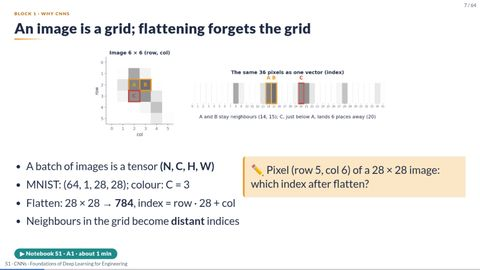

<sub>Slide 7 · An image is a grid; flattening forgets the grid</sub>

An MLP needs a vector, so we flatten the 28 × 28 grid into 784 numbers, row after row. The pixel in row 5, column 6 becomes entry 5 · 28 + 6 = **146**. Its right neighbour is entry 147, but the pixel just below it is entry 174: neighbours in the image can be far apart in the vector, and the MLP has no idea which inputs are neighbours.

In [ ]:
# ▶ S1·A1
print("X_train:", tuple(X_train.shape), "  (N, C, H, W)")
print("one image:", tuple(X_train[0].shape), "->", X_train[0].numel(), "numbers after flattening")

one_pixel = torch.zeros(28, 28)
one_pixel[5, 6] = 1.0                                    # row 5, column 6
idx = one_pixel.flatten().argmax().item()
print("pixel (row 5, col 6) becomes entry", idx, "of the 784-vector")
print("right neighbour (5, 7) ->", 5 * 28 + 7, " · pixel below (6, 6) ->", 6 * 28 + 6)
check(idx == 146, "flatten index = row · 28 + col = 5 · 28 + 6 = 146",
      "flattening is row-major: index = row * 28 + col")

show_grid(X_train[:8], [f"label {int(c)}" for c in y_train[:8]])

### ▶ S1·A2 · Your MLP breaks when the digit moves 3 pixels

*Slide: PYTHON EXERCISE S1·A2 (slide 10).*

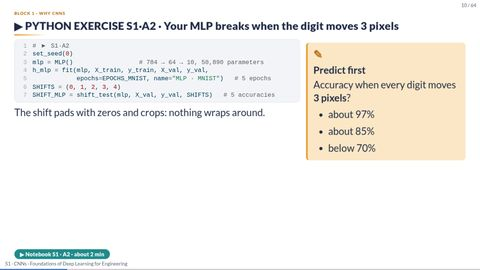

<sub>Slide 10 · Your MLP breaks when the digit moves 3 pixels</sub>

This is the MLP of Session 2: 784 → 64 → 10 (50,890 parameters), trained for 5 epochs with Adam. Then `shift_test` moves every validation digit 0 to 4 pixels to the right (the empty columns are black) and measures the accuracy again.

**Predict first.** The accuracy without shift is about 97%. What is it at a shift of 3 pixels: about 97%, about 85%, or below 70%?

In [ ]:
# ▶ S1·A2
class MLP(nn.Module):
    """The MLP of Session 2: flatten -> Linear(in_features, 64) -> ReLU -> Linear(64, 10)."""
    def __init__(self, in_features=784, hidden=64):
        super().__init__()
        self.net = nn.Sequential(nn.Flatten(), nn.Linear(in_features, hidden), nn.ReLU(),
                                 nn.Linear(hidden, 10))

    def forward(self, x):
        return self.net(x)                                # logits, no softmax


set_seed(0)
mlp = MLP()
print("MLP parameters:", f"{count_params(mlp):,}")
check(count_params(mlp) == 50890, "MLP 784 → 64 → 10 has 50,890 parameters, as in Session 2",
      "(784·64 + 64) + (64·10 + 10)")
h_mlp = fit(mlp, X_train, y_train, X_val, y_val, epochs=EPOCHS_MNIST, name="MLP · MNIST")

SHIFTS = (0, 1, 2, 3, 4)
SHIFT_MLP = shift_test(mlp, X_val, y_val, SHIFTS)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw=dict(width_ratios=[1, 2]))
ax[0].imshow(torch.cat([X_val[0, 0], shift_images(X_val[:1], 3)[0, 0]], dim=1).cpu(), cmap="gray")
ax[0].set_title("a digit, and the same digit 3 px to the right", fontsize=9); ax[0].axis("off")
ax[1].bar([str(s) for s in SHIFTS], [100 * a for a in SHIFT_MLP], color=MLP_COLOR)
for s, a in zip(SHIFTS, SHIFT_MLP):
    ax[1].text(s, 100 * a + 1, f"{100 * a:.1f}%", ha="center", fontsize=9)
ax[1].set_ylim(0, 105); ax[1].set_xlabel("shift (pixels)"); ax[1].set_ylabel("validation accuracy (%)")
ax[1].set_title("MLP: accuracy vs shift")
plt.tight_layout(); plt.show()
check(SHIFT_MLP[3] < SHIFT_MLP[0] - 0.05, "the MLP loses a lot of accuracy when the digit moves 3 pixels",
      "rerun S1·A2: the shift should hurt the MLP")

❓ **A2 question.** Your prediction for a shift of 3 pixels, and the number you got. Why does a 3-pixel move hurt the MLP so much, if a person reads the digit without trouble?

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

### ▶ S1·A3 · A hand-made kernel on a real digit

*Slide: PYTHON EXERCISE S1·A3 (slides 19 and 20).*

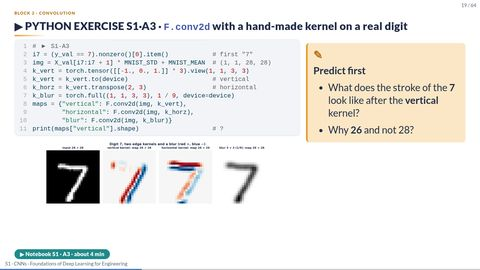 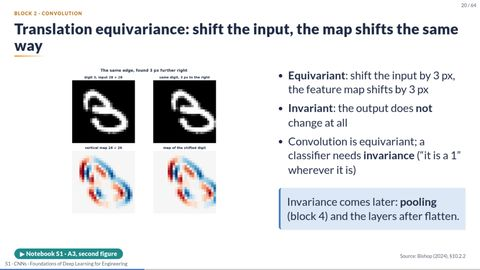

<sub>Slides 19 and 20 · F.conv2d with a hand-made kernel on a real digit | Translation equivariance: shift the input, the map shifts the same way</sub>

`F.conv2d(img, k)` slides the 3 × 3 kernel `k` over the image and, at each position, multiplies the 9 pixels under it by the 9 kernel numbers and adds them. Shapes: the image is `(N, C, H, W) = (1, 1, 28, 28)` and the kernel is `(C_out, C_in, M, M) = (1, 1, 3, 3)`.

- vertical kernel `[-1, 0, 1]` in every row: large where the image goes from dark (left) to bright (right), negative from bright to dark,
- horizontal kernel: the same, turned 90°,
- blur kernel: every entry 1/9, the mean of the neighbourhood.

**Predict first.** What does a vertical stroke look like after the vertical kernel? Why is the output 26 × 26 and not 28 × 28?

Then we move the digit 3 pixels to the right: the map moves 3 pixels too (**equivariance**).

In [ ]:
# ▶ S1·A3
i7 = (y_val == 7).nonzero()[0].item()                     # the first "7" of the validation set
img = X_val[i7:i7 + 1] * MNIST_STD + MNIST_MEAN           # back to [0, 1]; shape (1, 1, 28, 28)

k_vert = torch.tensor([[-1., 0., 1.]] * 3).view(1, 1, 3, 3).to(device)   # vertical edges
k_horz = k_vert.transpose(2, 3)                                          # horizontal edges
k_blur = torch.full((1, 1, 3, 3), 1 / 9, device=device)                  # local mean
maps = {"vertical": F.conv2d(img, k_vert), "horizontal": F.conv2d(img, k_horz),
        "blur": F.conv2d(img, k_blur)}
for name, m in maps.items():
    print(f"{name:10s} kernel -> output shape {tuple(m.shape)}, values from {m.min():.2f} to {m.max():.2f}")
check(maps["vertical"].shape == (1, 1, 26, 26), "a 3 × 3 kernel without padding: 28 → 26",
      "the kernel must fit inside the image: 28 − 3 + 1 = 26")

fig, ax = plt.subplots(1, 4, figsize=(12, 3.2))
ax[0].imshow(img[0, 0].cpu(), cmap="gray"); ax[0].set_title("digit (1, 1, 28, 28)")
for a, (name, m) in zip(ax[1:], maps.items()):
    v = m.abs().max().item()
    a.imshow(m[0, 0].cpu(), cmap=DIV_CMAP if name != "blur" else "gray", vmin=-v if name != "blur" else 0, vmax=v)
    a.set_title(f"{name} (1, 1, 26, 26)")
for a in ax:
    a.axis("off")
plt.suptitle("teal = positive, red = negative", fontsize=9); plt.tight_layout(); plt.show()

# ---- equivariance: shift the digit, the map shifts by the same amount
img_s = shift_images(img, 3, fill=0.0)
m, m_s = F.conv2d(img, k_vert), F.conv2d(img_s, k_vert)
fig, ax = plt.subplots(1, 4, figsize=(12, 3.2))
v = m.abs().max().item()
for a, x, t in zip(ax, [img, m, img_s, m_s], ["digit", "vertical map", "digit, 3 px right", "its vertical map"]):
    a.imshow(x[0, 0].cpu(), cmap="gray" if "map" not in t else DIV_CMAP,
             vmin=None if "map" not in t else -v, vmax=None if "map" not in t else v)
    a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()
check(torch.allclose(m_s[..., 3:], m[..., :-3], atol=1e-5),
      "shift the digit 3 px → the feature map shifts 3 px (equivariance)",
      "compare columns 3..25 of the shifted map with columns 0..22 of the original map")

❓ **A3 question.** Why is the output 26 × 26 and not 28 × 28? How many different numbers (weights) does the vertical kernel use to produce all 26 · 26 = 676 outputs?

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

### ▶ S1·A4 · Predict the output shape of three `nn.Conv2d` settings

*Slide: PYTHON EXERCISE S1·A4 (slide 28).*

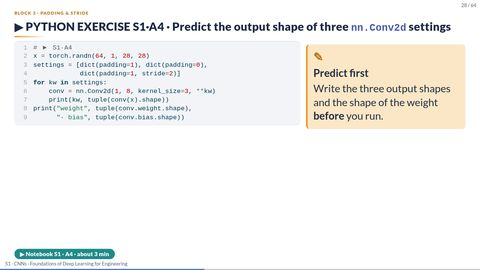

<sub>Slide 28 · Predict the output shape of three nn.Conv2d settings</sub>

A batch of 64 MNIST-like images `(64, 1, 28, 28)` goes through `nn.Conv2d(1, 8, 3, ...)`: 8 filters of size 3 × 3. The output size per side is (J + 2P − M)/S + 1.

**Predict first** the three output shapes, then run: (a) `padding=1`, (b) `padding=0`, (c) `padding=1, stride=2`.

In [ ]:
# ▶ S1·A4
x = torch.randn(64, 1, 28, 28)
settings = [dict(padding=1), dict(padding=0), dict(padding=1, stride=2)]
expected = [(64, 8, 28, 28), (64, 8, 26, 26), (64, 8, 14, 14)]
for kw, exp in zip(settings, expected):
    conv = nn.Conv2d(1, 8, kernel_size=3, **kw)
    y = conv(x)
    print(f"nn.Conv2d(1, 8, 3, {', '.join(f'{k}={v}' for k, v in kw.items())}): {tuple(x.shape)} -> {tuple(y.shape)}")
    check(tuple(y.shape) == exp, f"output {exp}", "(J + 2P − M)/S + 1 with J = 28, M = 3")
print("weight", tuple(conv.weight.shape), "· bias", tuple(conv.bias.shape), "· parameters", count_params(conv))
check(tuple(conv.weight.shape) == (8, 1, 3, 3) and tuple(conv.bias.shape) == (8,),
      "weight (C_out, C_in, M, M) = (8, 1, 3, 3) and one bias per filter: 8 · 9 + 8 = 80 parameters",
      "weight shape is (out_channels, in_channels, kernel, kernel)")

### ▶ S1·A5 · Max-pooling the Bishop matrix, then the edge maps

*Slide: PYTHON EXERCISE S1·A5 (slide 39).*

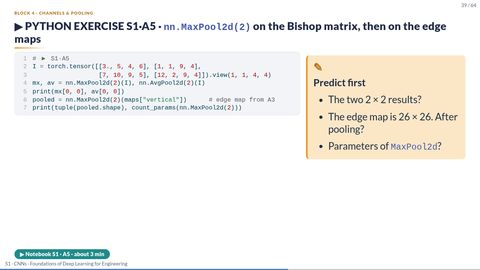

<sub>Slide 39 · nn.MaxPool2d(2) on the Bishop matrix, then on the edge maps</sub>

`nn.MaxPool2d(2)` keeps the largest value of every 2 × 2 block; `nn.AvgPool2d(2)` keeps the mean. Both halve the height and the width and have **no parameters**. Check the hand result of the slides on the 4 × 4 matrix of Bishop (2024), §10.2.5, then pool the vertical-edge map of S1·A3: 26 × 26 → 13 × 13.

In [ ]:
# ▶ S1·A5
I = torch.tensor([[3., 5, 4, 6], [1, 1, 9, 4], [7, 10, 9, 5], [12, 2, 9, 4]]).view(1, 1, 4, 4)
mx, av = nn.MaxPool2d(2)(I), nn.AvgPool2d(2)(I)
print("max-pool:\n", mx[0, 0])
print("average-pool:\n", av[0, 0])
check(torch.equal(mx[0, 0], torch.tensor([[5., 9], [12, 9]])), "max-pool → [[5, 9], [12, 9]]",
      "largest value of each 2 × 2 block")
check(torch.allclose(av[0, 0], torch.tensor([[2.5, 5.75], [7.75, 6.75]])),
      "average-pool → [[2.5, 5.75], [7.75, 6.75]]", "mean of each 2 × 2 block")
check(count_params(nn.MaxPool2d(2)) == 0, "pooling has 0 parameters", "nothing to learn in a max")

pooled = nn.MaxPool2d(2)(maps["vertical"])
print("vertical map", tuple(maps["vertical"].shape), "-> pooled", tuple(pooled.shape))
check(tuple(pooled.shape) == (1, 1, 13, 13), "26 × 26 → 13 × 13 after max-pooling", "pool size 2, stride 2")
fig, ax = plt.subplots(1, 2, figsize=(6.5, 3.2))
v = maps["vertical"].abs().max().item()
for a, x, t in zip(ax, [maps["vertical"], pooled], ["vertical map 26 × 26", "max-pooled 13 × 13"]):
    a.imshow(x[0, 0].cpu(), cmap=DIV_CMAP, vmin=-v, vmax=v); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

### ▶ S1·A6 · `ConvNet` as an `nn.Module`, and its parameter count

*Slide: PYTHON EXERCISE S1·A6 (slide 48).*

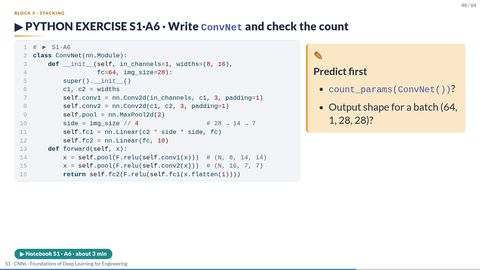

<sub>Slide 48 · Write ConvNet and check the count</sub>

| layer | output shape | parameters |
|:-|:-|-:|
| input | (N, 1, 28, 28) | |
| conv(1 → 8, 3 × 3, padding 1) + ReLU | (N, 8, 28, 28) | (9 · 1 + 1) · 8 = 80 |
| max-pool 2 | (N, 8, 14, 14) | 0 |
| conv(8 → 16, 3 × 3, padding 1) + ReLU | (N, 16, 14, 14) | (9 · 8 + 1) · 16 = 1,168 |
| max-pool 2 | (N, 16, 7, 7) | 0 |
| flatten | (N, 784) | 0 |
| Linear(784, 64) + ReLU | (N, 64) | 784 · 64 + 64 = 50,240 |
| Linear(64, 10) | (N, 10) | 650 |
| **total** | | **52,138** |

The class takes `in_channels` and `img_size`, so the same code works on CIFAR-10 (3 channels, 32 × 32) in S1·A9. There is **no softmax** in `forward`: `nn.CrossEntropyLoss` takes the raw scores (logits).

In [ ]:
# ▶ S1·A6
class ConvNet(nn.Module):
    """conv(C→8, 3×3, pad 1) → ReLU → pool 2 → conv(8→16, 3×3, pad 1) → ReLU → pool 2
    → flatten → Linear(16·(H/4)·(W/4), 64) → ReLU → Linear(64, 10)."""
    def __init__(self, in_channels=1, widths=(8, 16), fc=64, img_size=28):
        super().__init__()
        c1, c2 = widths
        self.conv1 = nn.Conv2d(in_channels, c1, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(c1, c2, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2)
        side = img_size // 4                       # two poolings: 28 → 14 → 7 (32 → 16 → 8)
        self.fc1 = nn.Linear(c2 * side * side, fc)
        self.fc2 = nn.Linear(fc, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))       # (N, 8, 14, 14)
        x = self.pool(F.relu(self.conv2(x)))       # (N, 16, 7, 7)
        x = x.flatten(1)                           # (N, 784)
        x = F.relu(self.fc1(x))                    # (N, 64)
        return self.fc2(x)                         # (N, 10) logits, no softmax


set_seed(0)
cnn = ConvNet()
print(cnn)
for name, layer in cnn.named_children():
    print(f"  {name:6s} {count_params(layer):>7,} parameters")
print(f"  total  {count_params(cnn):>7,}   (MLP: {count_params(mlp):,})")
out = cnn(torch.randn(64, 1, 28, 28))
print("output shape:", tuple(out.shape))
check(count_params(cnn) == 52138, "ConvNet has 52,138 parameters, almost the same as the MLP (50,890)",
      "80 + 1,168 + 50,240 + 650: check padding=1 and the flatten size 16·7·7 = 784")
check(tuple(out.shape) == (64, 10), "64 images in, 64 × 10 logits out", "the last layer must return 10 scores")

❓ **A6 question.** Which layer holds most of the 52,138 parameters: conv1, conv2, fc1 or fc2? What does this tell you about where a CNN spends its parameters?

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

### ▶ S1·A7 · CNN vs MLP on MNIST: same parameters, fewer errors

*Slide: Block 6, "Training a CNN is the same four steps" (slide 51).*

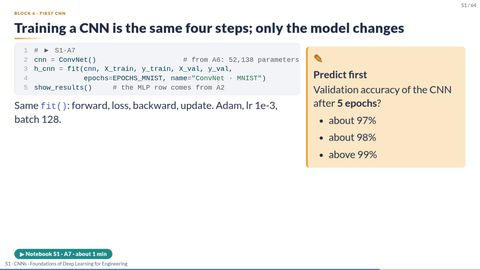

<sub>Slide 51 · Training a CNN is the same four steps; only the model changes</sub>

Same data, same `fit` (Adam, learning rate 0.001, batch 128, 5 epochs), almost the same number of parameters. Only the architecture changes. The table counts the errors on the 10,000 validation images.

In [ ]:
# ▶ S1·A7
h_cnn = fit(cnn, X_train, y_train, X_val, y_val, epochs=EPOCHS_MNIST, name="ConvNet · MNIST")
show_results()
acc_mlp, acc_cnn = result("MLP · MNIST")["val_acc"], result("ConvNet · MNIST")["val_acc"]
print(f"\nerrors: MLP {result('MLP · MNIST')['errors']:,} · ConvNet {result('ConvNet · MNIST')['errors']:,}"
      f" (out of {len(y_val):,})")
check(acc_cnn > (0.85 if FAST else 0.95),        # reference run: 98.2% after 5 epochs
      f"ConvNet reaches {100 * acc_cnn:.1f}% on MNIST validation",
      "rerun S1·A6 and S1·A7 (the model must be created again before training)")
if not FAST:
    check(acc_cnn > acc_mlp, "the CNN makes fewer errors than the MLP with about the same number of parameters",
          "train both for the same number of epochs")

### ▶ S1·A8 · The shift test again: MLP vs CNN

*Slide: Block 6, shift test (slide 52).*

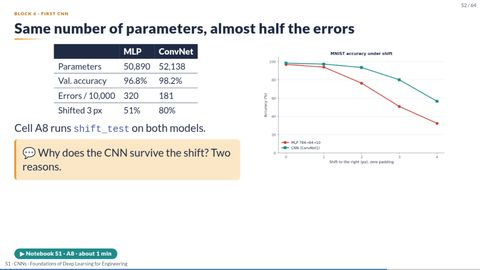

<sub>Slide 52 · Same number of parameters, almost half the errors</sub>

The same shifted images for both models. The convolutions are equivariant (the maps move with the digit) and the max-pooling absorbs small moves, so the CNN degrades much more slowly.

In [ ]:
# ▶ S1·A8
print("MLP");     SHIFT_MLP = shift_test(mlp, X_val, y_val, SHIFTS)
print("ConvNet"); SHIFT_CNN = shift_test(cnn, X_val, y_val, SHIFTS)

w = 0.38
xs = np.arange(len(SHIFTS))
plt.figure(figsize=(7.5, 3.4))
plt.bar(xs - w / 2, [100 * a for a in SHIFT_MLP], w, color=MLP_COLOR, label=f"MLP ({count_params(mlp):,} params)")
plt.bar(xs + w / 2, [100 * a for a in SHIFT_CNN], w, color=CNN_COLOR, label=f"ConvNet ({count_params(cnn):,} params)")
plt.xticks(xs, SHIFTS); plt.xlabel("shift (pixels)"); plt.ylabel("validation accuracy (%)")
plt.ylim(0, 105); plt.legend(loc="lower left"); plt.title("Accuracy when the digit moves to the right")
plt.tight_layout(); plt.show()
if FAST:
    print("(FAST mode: models trained for 1 epoch on 10,000 images, comparison not checked)")
else:
    check(SHIFT_CNN[3] > SHIFT_MLP[3] + 0.10, "at 3 px the CNN keeps much more accuracy than the MLP",
          "rerun S1·A2 and S1·A7 first")

### ▶ S1·A9 · Colour images: CIFAR-10, the gap grows

*Slides: Block 6, CIFAR-10 (slides 53 and 54).*

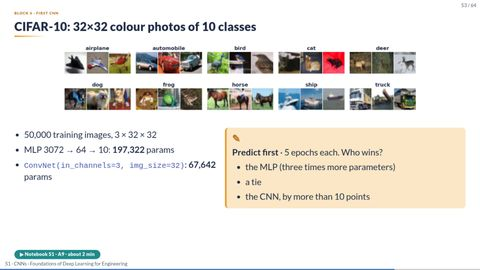 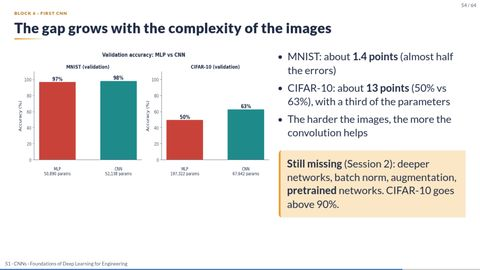

<sub>Slides 53 and 54 · CIFAR-10: 32×32 colour photos of 10 classes | The gap grows with the complexity of the images</sub>

Now 3 × 32 × 32 colour photos. The MLP must flatten 3 · 32 · 32 = 3,072 inputs, so its first layer grows to 3,072 · 64 + 64 = 196,672 weights. The ConvNet only changes `in_channels=3` (conv1: (9 · 3 + 1) · 8 = 224) and the flatten size 16 · 8 · 8 = 1,024.

**Predict first.** Which model has more parameters now, and which one will be more accurate?

In [ ]:
# ▶ S1·A9
# 4 examples of each class (one class per column)
idx = [(yc_val == c).nonzero()[:4, 0] for c in range(10)]
sel = torch.stack(idx, dim=1).flatten()
show_grid(Xc_val[sel] * CIFAR_STD.to(device) + CIFAR_MEAN.to(device),
          [CIFAR_CLASSES[c] for c in range(10)], ncols=10, size=1.1)

set_seed(0)
mlp_c = MLP(in_features=C_IN_C * HW_C * HW_C)
cnn_c = ConvNet(in_channels=C_IN_C, img_size=HW_C)
print(f"{DS_C}: MLP {C_IN_C * HW_C * HW_C:,} → 64 → 10: {count_params(mlp_c):,} parameters")
print(f"{DS_C}: ConvNet(in_channels={C_IN_C}, img_size={HW_C}): {count_params(cnn_c):,} parameters")
print("output:", tuple(cnn_c(Xc_val[:4].cpu()).shape))
check(count_params(mlp_c) == (197322 if CIFAR_OK else 50890),
      "MLP 3,072 → 64 → 10 has 197,322 parameters", "(3,072·64 + 64) + (64·10 + 10)")
check(count_params(cnn_c) == (67642 if CIFAR_OK else 52138),
      "ConvNet on CIFAR-10 has 67,642 parameters (flatten 16·8·8 = 1,024)",
      "in_channels=3 and img_size=32 in ConvNet(...)")

Training both models for 5 epochs on 50,000 colour images takes a few seconds on a T4 GPU (a few minutes on a CPU).

In [ ]:
# ▶ S1·A9·fit
h_mlp_c = fit(mlp_c, Xc_train, yc_train, Xc_val, yc_val, epochs=EPOCHS_CIFAR, name=f"MLP · {DS_C}")
h_cnn_c = fit(cnn_c, Xc_train, yc_train, Xc_val, yc_val, epochs=EPOCHS_CIFAR, name=f"ConvNet · {DS_C}")
show_results()

rows = [("MNIST", result("MLP · MNIST"), result("ConvNet · MNIST")),
        (DS_C, result(f"MLP · {DS_C}"), result(f"ConvNet · {DS_C}"))]
w, xs = 0.38, np.arange(2)
plt.figure(figsize=(7.5, 3.6))
for k, (ds, r_mlp, r_cnn) in enumerate(rows):
    for dx, r, col in [(-w / 2, r_mlp, MLP_COLOR), (w / 2, r_cnn, CNN_COLOR)]:
        plt.bar(k + dx, 100 * r["val_acc"], w, color=col)
        plt.text(k + dx, 100 * r["val_acc"] + 1, f"{100 * r['val_acc']:.1f}%\n{r['params']:,} p",
                 ha="center", fontsize=8)
plt.bar(0, 0, color=MLP_COLOR, label="MLP"); plt.bar(0, 0, color=CNN_COLOR, label="ConvNet")
plt.xticks(xs, [r[0] for r in rows]); plt.ylim(0, 115); plt.ylabel("validation accuracy (%)")
plt.legend(loc="upper right"); plt.title("MLP vs CNN: the gap grows on colour images")
plt.tight_layout(); plt.show()
acc_mlp_c, acc_cnn_c = result(f"MLP · {DS_C}")["val_acc"], result(f"ConvNet · {DS_C}")["val_acc"]
if FAST:
    print("(FAST mode: models trained for 1 epoch on 10,000 images, comparison not checked)")
else:
    check(acc_cnn_c > acc_mlp_c,
          f"on {DS_C} the ConvNet ({100 * acc_cnn_c:.1f}%) beats the MLP ({100 * acc_mlp_c:.1f}%) "
          "with about one third of the parameters", "rerun S1·A9 from the cell above")

### ▶ S1·A9b · Save the reference numbers

This cell writes the numbers of Part A to `s1_reference.json` (the lecturer uses it for the slides). You can ignore it; it never stops the notebook.

In [ ]:
# ▶ S1·A9b
def save_reference(path=None, quiet=False):
    """Write the Part A (and TODO 5) numbers to a small json file. Never raises."""
    try:
        path = path or ("s1_reference_fast.json" if FAST else "s1_reference.json")

        def row(name, shift=None):
            rs = [r for r in RESULTS if r["name"] == name]
            if not rs:
                return {"params": 0, "val_acc": 0.0}
            d = {"params": rs[-1]["params"], "val_acc": round(rs[-1]["val_acc"], 4),
                 "errors": rs[-1]["errors"], "n_val": rs[-1]["n_val"], "time_s": rs[-1]["time_s"]}
            if shift is not None:
                d["shift"] = [round(a, 4) for a in shift]
            return d

        ref = {"mnist": {"mlp": row("MLP · MNIST", SHIFT_MLP), "cnn": row("ConvNet · MNIST", SHIFT_CNN)},
               "cifar": {"mlp": row(f"MLP · {DS_C}"), "cnn": row(f"ConvNet · {DS_C}"),
                         "convnet2": row(f"ConvNet2 · {DS_C}")},
               "device": device, "epochs": {"mnist": EPOCHS_MNIST, "cifar": EPOCHS_CIFAR},
               "shifts": list(SHIFTS), "cifar_ok": CIFAR_OK, "fast": FAST,
               "n_train": {"mnist": len(X_train), "cifar": len(Xc_train)},
               "n_val": {"mnist": len(X_val), "cifar": len(Xc_val)},
               "torch": torch.__version__, "all_results": RESULTS}
        with open(path, "w") as f:
            json.dump(ref, f, indent=1, ensure_ascii=False)
        if not quiet:
            print("reference numbers written to", path)
    except Exception as e:                                # never break the notebook
        print("(could not write the reference file:", repr(e)[:100], ")")


save_reference()

## Part B · Workshop (in pairs, about 35 minutes)

*Slide: "Your turn: notebook Part B" (slide 55); each TODO below shows its own guide slide (56 to 60).*

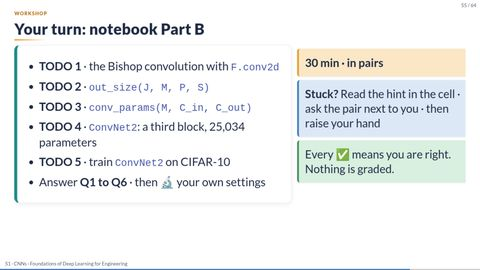

<sub>Slide 55 · Your turn: notebook Part B</sub>

Five TODOs, six questions and one free experiment. Replace every `___`, run the cell, then run the ✅ cell below it. Stuck? Read the hint, ask the pair next to you, then raise your hand.

### ✏️ TODO 1 · Convolution by hand, then in code

*Slide: TODO 1 guide (slide 56).*

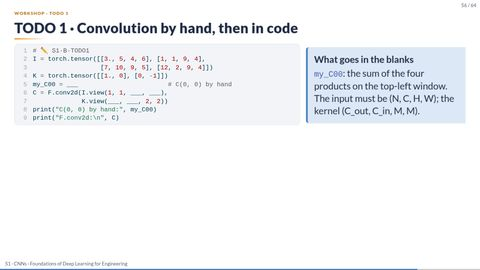

<sub>Slide 56 · TODO 1 · Convolution by hand, then in code</sub>

The 4 × 4 image and the 2 × 2 kernel of Bishop (2024), Fig. 10.3:

$$I = \begin{pmatrix}3&5&4&6\\1&1&9&4\\7&10&9&5\\12&2&9&4\end{pmatrix},\qquad K = \begin{pmatrix}1&0\\0&-1\end{pmatrix}$$

1. **By hand**: put K on the top-left 2 × 2 window, multiply entry by entry and add. That is C(0, 0). Write the sum in `my_C00`.
2. **In code**: `F.conv2d` wants the image as `(N, C, H, W)` and the kernel as `(C_out, C_in, M, M)`. Fill in the `view` sizes.

In [ ]:
# ✏️ S1·B·TODO1
I = torch.tensor([[3., 5, 4, 6], [1, 1, 9, 4], [7, 10, 9, 5], [12, 2, 9, 4]])   # (4, 4)
K = torch.tensor([[1., 0], [0, -1]])                                           # (2, 2)

my_C00 = ___          # C(0, 0) by hand

C = F.conv2d(I.view(1, 1, ___, ___), K.view(___, ___, 2, 2))
print("C(0, 0) by hand:", my_C00)
print("F.conv2d:\n", C)

In [ ]:
# ▶ S1·B·TODO1·check
expected = torch.tensor([[2., -4, 0], [-9, -8, 4], [5, 1, 5]])
check(my_C00 == 2, "C(0, 0) = 3·1 + 5·0 + 1·0 + 1·(−1) = 2",
      "multiply the window [[3, 5], [1, 1]] by K entry by entry and add the four products")
check(tuple(C.shape) == (1, 1, 3, 3), "a 2 × 2 kernel on a 4 × 4 image gives (1, 1, 3, 3)",
      "image as (N, C, H, W) = (1, 1, 4, 4) and kernel as (C_out, C_in, M, M) = (1, 1, 2, 2)")
check(torch.equal(C.view(3, 3), expected), "F.conv2d gives [[2, −4, 0], [−9, −8, 4], [5, 1, 5]], as Bishop",
      "(N, C, H, W) and (C_out, C_in, M, M)")

### ✏️ TODO 2 · The output-size formula

*Slide: TODO 2 guide (slide 57).*

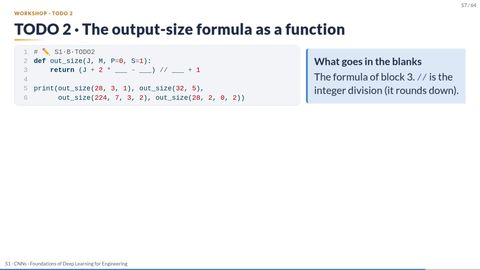

<sub>Slide 57 · TODO 2 · The output-size formula as a function</sub>

For an input of size J, a kernel M, padding P and stride S, the output size is

$$\frac{J + 2P - M}{S} + 1 \quad\text{(rounded down)}$$

Write it as a function. Use `//` (integer division).

In [ ]:
# ✏️ S1·B·TODO2
def out_size(J, M, P=0, S=1):
    """Output size of a convolution or pooling: input J, kernel M, padding P, stride S."""
    return (J + 2 * ___ - ___) // ___ + 1


print(out_size(28, 3, 1), out_size(32, 5), out_size(224, 7, 3, 2), out_size(28, 2, 0, 2))

In [ ]:
# ▶ S1·B·TODO2·check
check(out_size(28, 3, 1) == 28, "(28 + 2 − 3)/1 + 1 = 28: padding 1 keeps the size of a 3 × 3 conv",
      "2 * P, minus M, divided by S, plus 1")
check(out_size(32, 5) == 28, "(32 − 5)/1 + 1 = 28 (LeNet's first layer)", "P = 0 and S = 1 by default")
check(out_size(224, 7, 3, 2) == 112, "(224 + 6 − 7)//2 + 1 = 112 (ResNet's first layer)", "use // for the division")
check(out_size(28, 2, 0, 2) == 14, "pooling 2 × 2 with stride 2: 28 → 14", "a pooling window is a kernel with M = 2, S = 2")
y = nn.Conv2d(1, 1, 5)(torch.zeros(1, 1, 32, 32))
check(y.shape[-1] == out_size(32, 5), f"your formula agrees with nn.Conv2d(1, 1, 5) on 32 × 32 ({y.shape[-1]})",
      "compare with the shape printed by PyTorch")

❓ **Q1.** What is `out_size(64, 5, 2, 2)`? Compute it by hand first, then check with your function.
(a) 30  (b) 31  (c) 32  (d) 64

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

### ✏️ TODO 3 · Counting the parameters of a convolution

*Slide: TODO 3 guide (slide 58).*

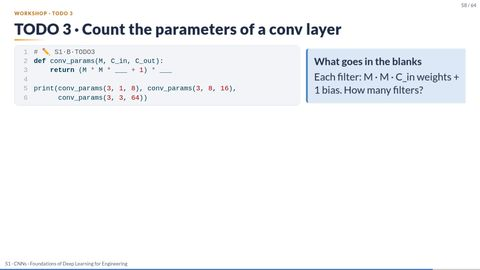

<sub>Slide 58 · TODO 3 · Count the parameters of a conv layer</sub>

`nn.Conv2d(C_in, C_out, M)` has C_out filters. Each filter sees **all** the input channels, so it has M · M · C_in weights plus 1 bias:

$$(M^2 \cdot C_{in} + 1)\cdot C_{out}$$

In [ ]:
# ✏️ S1·B·TODO3
def conv_params(M, C_in, C_out):
    """Weights and biases of nn.Conv2d(C_in, C_out, M)."""
    return (M * M * ___ + 1) * ___


print(conv_params(3, 1, 8), conv_params(3, 8, 16), conv_params(3, 3, 64))

In [ ]:
# ▶ S1·B·TODO3·check
check(conv_params(3, 1, 8) == 80, "conv(1 → 8, 3 × 3): (9·1 + 1)·8 = 80", "M * M * C_in weights per filter, plus 1 bias")
check(conv_params(3, 8, 16) == 1168, "conv(8 → 16, 3 × 3): (9·8 + 1)·16 = 1,168", "each filter sees all 8 input channels")
check(conv_params(3, 3, 64) == 1792, "conv(3 → 64, 3 × 3): (9·3 + 1)·64 = 1,792 (VGG's first layer)",
      "multiply by C_out at the end")
check(conv_params(3, 16, 32) == count_params(nn.Conv2d(16, 32, 3)), "your formula agrees with PyTorch: 4,640",
      "compare with count_params(nn.Conv2d(16, 32, 3))")

❓ **Q4.** On CIFAR-10 the MLP has 197,322 parameters and the ConvNet 67,642 (S1·A9). On MNIST they had 50,890 and 52,138. Which **single layer** explains most of the growth in each model? Give the numbers.

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

### ✏️ TODO 4 · A deeper network: `ConvNet2` with three blocks

*Slide: TODO 4 guide (slide 59).*

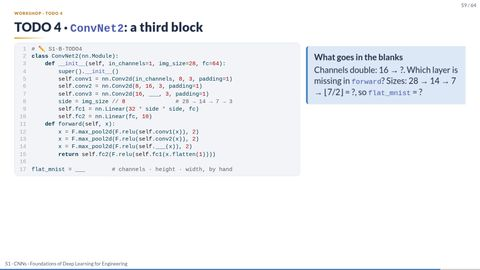

<sub>Slide 59 · TODO 4 · ConvNet2: a third block</sub>

Add a third block conv(16 → 32, 3 × 3, padding 1) → ReLU → max-pool 2. On MNIST the size goes 28 → 14 → 7 → 3 (max-pooling rounds 7/2 down), so the flatten size is 32 · 3 · 3. The class computes it from `img_size`, but write the MNIST value by hand in `flat_mnist`.

In [ ]:
# ✏️ S1·B·TODO4
class ConvNet2(nn.Module):
    """Three blocks conv → ReLU → max-pool 2 with 8, 16, 32 channels, then Linear(·, 64) → ReLU → Linear(64, 10)."""
    def __init__(self, in_channels=1, img_size=28, fc=64):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, 8, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(8, 16, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(16, ___, kernel_size=3, padding=1)
        side = img_size // 8                   # three poolings: 28 → 14 → 7 → 3 (32 → 16 → 8 → 4)
        self.fc1 = nn.Linear(32 * side * side, fc)
        self.fc2 = nn.Linear(fc, 10)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), 2)
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        x = F.max_pool2d(F.relu(self.___(x)), 2)
        x = x.flatten(1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)                     # logits, no softmax


flat_mnist = ___                             # by hand: channels · height · width after the third pooling
set_seed(0)
net2 = ConvNet2()
out = net2(torch.randn(64, 1, 28, 28))
print("output", tuple(out.shape), "·", f"{count_params(net2):,}", "parameters")

In [ ]:
# ▶ S1·B·TODO4·check
check(tuple(out.shape) == (64, 10), "64 images in, 64 × 10 logits out", "forward must use conv1, conv2 and conv3")
check(flat_mnist == 288 and net2.fc1.in_features == 288, "flatten size 32 · 3 · 3 = 288 (28 → 14 → 7 → 3)",
      "7 // 2 = 3: max-pooling rounds down")
check(count_params(net2) == 25034,
      "ConvNet2 has 25,034 parameters: 80 + 1,168 + 4,640 + 18,496 + 650, half of ConvNet (52,138)",
      "conv3 is nn.Conv2d(16, 32, 3, padding=1)")

❓ **Q2.** What is the receptive field of one output of `conv3` in `ConvNet2` (how many input pixels per side can influence it)? Use: a 3 × 3 conv adds 2 · (current jump), a 2 × 2 pooling adds 1 · (current jump) and doubles the jump.
(a) 7 × 7  (b) 10 × 10  (c) 18 × 18  (d) 28 × 28

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

### ✏️ TODO 5 · Train `ConvNet2` on CIFAR-10

*Slide: TODO 5 guide (slide 60).*

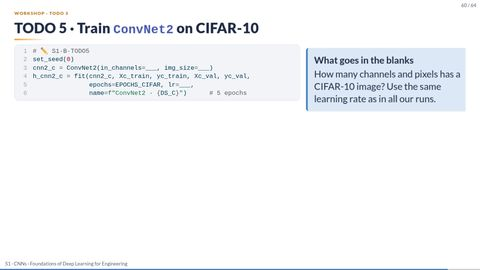

<sub>Slide 60 · TODO 5 · Train ConvNet2 on CIFAR-10</sub>

CIFAR-10 images have 3 colour channels and 32 × 32 pixels; the flatten size becomes 32 · 4 · 4 = 512. Use the same learning rate as in all our runs. Training takes a few seconds on a T4 GPU.

In [ ]:
# ✏️ S1·B·TODO5
set_seed(0)
cnn2_c = ConvNet2(in_channels=___, img_size=___)
if not CIFAR_OK:                                   # Fashion-MNIST fallback: 1 channel, 28 × 28
    cnn2_c = ConvNet2(in_channels=1, img_size=28)
print(f"ConvNet2 on {DS_C}: {count_params(cnn2_c):,} parameters")
h_cnn2_c = fit(cnn2_c, Xc_train, yc_train, Xc_val, yc_val, epochs=EPOCHS_CIFAR, lr=___,
               name=f"ConvNet2 · {DS_C}")

In [ ]:
# ▶ S1·B·TODO5·check
acc2 = h_cnn2_c["val_acc"][-1]
threshold = 0.30 if FAST else 0.58          # reference run: 61.6% after 5 epochs (FAST: 1 epoch, 10,000 images)
show_results()
check(cnn2_c.fc1.in_features == (512 if CIFAR_OK else 288), "flatten size 32 · 4 · 4 = 512 on 32 × 32 images",
      "in_channels=3 (RGB) and img_size=32")
check(acc2 > threshold, f"ConvNet2 reaches {100 * acc2:.1f}% on {DS_C} validation (> {100 * threshold:.0f}%)",
      "lr=1e-3 as in the other runs; create the model again before training")

💬 **Q5.** On CIFAR-10, `ConvNet2` has fewer parameters than `ConvNet` (39,514 vs 67,642), yet its accuracy is similar. Where did the parameters go, and why does a third block not hurt?

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

💬 **Q3.** In S1·A8, at a shift of 3 pixels, the CNN kept much more of its accuracy than the MLP (about 80% vs 51% in the reference run). Explain why in two or three sentences. Use the words *shared weights*, *equivariant* and *pooling*.

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

💬 **Q6.** *Data augmentation* adds transformed copies of the training images. Which transformation would help on CIFAR-10 but hurt on MNIST: a horizontal flip, a small shift, or a small change of brightness? Why?

✍️ **Your answer:** *(double-click here and write)*

&nbsp;

### 🔬 Free experiment: your own CNN

Change `MY_SETTINGS` and run the two cells. Each run adds a row to the results table. Ideas:

- wider: `widths=(32, 64)`; deeper: `widths=(8, 16, 32)`,
- larger kernels: `kernel_size=5`,
- no pooling, stride 2 instead: `use_pool=False`,
- more epochs: `epochs=10`, or the other dataset: `dataset="cifar"`.

Keep an eye on the parameter count and on the time per epoch. Which change gives the best accuracy per parameter?

In [ ]:
# ▶ S1·B·EXP
MY_SETTINGS = dict(
    dataset="mnist",        # "mnist" or "cifar"
    widths=(16, 32),        # channels of each conv block, e.g. (8, 16), (32, 64), (8, 16, 32)
    kernel_size=3,          # 3 or 5 (padding = kernel_size // 2 keeps the size)
    use_pool=True,          # False: no pooling, each conv uses stride 2 instead
    epochs=5,
)


def make_model(settings):
    """Build a CNN from the settings: blocks conv → ReLU (→ max-pool), then Linear(·, 64) → ReLU → Linear(64, 10)."""
    c, size = (1, 28) if settings["dataset"] == "mnist" else (C_IN_C, HW_C)
    k, layers = settings["kernel_size"], []
    for w in settings["widths"]:
        layers += [nn.Conv2d(c, w, k, padding=k // 2, stride=1 if settings["use_pool"] else 2), nn.ReLU()]
        if settings["use_pool"]:
            layers.append(nn.MaxPool2d(2))
        c = w
    features = nn.Sequential(*layers)
    with torch.no_grad():                         # the flatten size, from one dummy image
        n_flat = features(torch.zeros(1, 1 if settings["dataset"] == "mnist" else C_IN_C, size, size)).numel()
    return nn.Sequential(features, nn.Flatten(), nn.Linear(n_flat, 64), nn.ReLU(), nn.Linear(64, 10))


set_seed(0)
my_model = make_model(MY_SETTINGS)
print(my_model)
print(f"{count_params(my_model):,} parameters")

In [ ]:
# ▶ S1·B·EXP·run
s = MY_SETTINGS
data = (X_train, y_train, X_val, y_val) if s["dataset"] == "mnist" else (Xc_train, yc_train, Xc_val, yc_val)
label = (f"🔬 {'MNIST' if s['dataset'] == 'mnist' else DS_C} w={s['widths']} k={s['kernel_size']} "
         f"{'pool' if s['use_pool'] else 'stride2'}")
h_my = fit(my_model, *data, epochs=1 if FAST else s["epochs"], name=label)
show_results()

## Summary

| Block | Idea | PyTorch line |
|:-|:-|:-|
| 1 · Why CNNs | flattening forgets the grid; the MLP breaks when the digit moves | `x.flatten(1)` |
| 2 · Convolution | one small kernel slid over the image: shared weights, a feature detector, equivariant to shifts | `F.conv2d(img, k)` |
| 3 · Padding, stride | output size (J + 2P − M)/S + 1; padding 1 keeps the size of a 3 × 3 conv | `nn.Conv2d(1, 8, 3, padding=1, stride=2)` |
| 4 · Channels, pooling | a filter sees all input channels: (M² · C_in + 1) · C_out parameters; pooling halves H and W with 0 parameters | `nn.Conv2d(3, 8, 3)`, `nn.MaxPool2d(2)` |
| 5 · Stacking | ReLU between convs; the receptive field grows; most parameters sit in the first dense layer | `class ConvNet(nn.Module)` |
| 6 · CNN vs MLP | same parameters, fewer errors, robust to shifts; the gap grows on colour images | `fit(cnn, X_train, y_train, X_val, y_val)` |

**Next session (CNN II):** famous architectures (LeNet, VGG, ResNet), what CNNs learn (filters, Grad-CAM), and transfer learning with a pretrained ResNet18.

The last cell prints your complete results table.

In [ ]:
# ▶ S1·END
show_results()
save_reference(quiet=True)                         # update the reference file with TODO 5 (ignore)